<a href="https://colab.research.google.com/github/starkjiang/TrAC-Interpretability/blob/main/Interpretability_in_Ag_LR_RF_DL_Week_2_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌽 Interpretability in AI: Opening the Black Box in Agriculture
### Linear regression · Random forests · Deep nets & feature visualization
**Translational AI Center (TrAC), Iowa State University**: live session, ~50 min

> **Before you start:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all` (≈2–3 min).
> Part 3 also works on a CPU, just more slowly.

| ⏱ Time | Part | The question we answer |
|---|---|---|
| 0–5 min | **Why interpretability in ag?** | Why should an agronomist trust a model? |
| 5–17 min | **Part 1: Linear regression** | What do coefficients *really* tell us? |
| 17–32 min | **Part 2: Random forest** | Which inputs matter, and *how* do they act? |
| 32–47 min | **Part 3: Deep learning** | What does a neural net *see* in a corn photo? |
| 47–50 min | **Wrap-up** | Reveal the answer key + takeaways |

## Why interpretability in agriculture?

* **Trust & adoption:** a grower or agronomist won't change a nitrogen rate because "the model said so."
* **Science:** does the model *rediscover agronomy* (the N-response plateau, heat stress), or has it found something new?
* **Debugging:** models take shortcuts. Plant-disease classifiers have been shown to pick up on **photo backgrounds and lighting** instead of lesions.
* **Accountability:** input decisions (N, crop protection) carry economic, environmental and regulatory consequences.

**Three kinds of questions you can ask a model**

| Scope | Question | Today's tools |
|---|---|---|
| 🌍 Global | What does the model do *overall*? | coefficients, feature importance, partial dependence |
| 📍 Local | Why *this* prediction for *this* field or image? | ICE curves, what-if analysis, Grad-CAM |
| 🔬 Mechanistic | What do the model's *internal units* represent? | feature visualization |

In [1]:
#@title ⚙️ Setup (imports & plotting style)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_TRUE, C_LIN, C_RF = "#2b2b2b", "#d1495b", "#2e86ab"   # truth, linear, random forest
print("Ready ✔")

Ready ✔


---
# Part 1: Linear regression: "the most interpretable model"?

### Our data: 800 simulated Iowa corn fields 🌽
We **simulate** the fields on purpose, because then we hold the *answer key*: we know exactly how each input
truly affects yield. That lets us check whether each interpretability method tells the truth.

| Column | Meaning |
|---|---|
| `nitrogen_lb_ac` | N fertilizer applied (lb/acre) |
| `rain_in` | growing-season rainfall (inches) |
| `soil_moisture_pct` | July soil moisture sensor reading (%) |
| `heat_days` | days above 95 °F during the season |
| `organic_matter_pct` | soil organic matter (%) |
| `soil_pH` | soil pH |
| `planting_doy` | planting date (day of year; 120 ≈ April 30) |
| `field_id` | an ID number that slipped into the spreadsheet 🙃 |
| **`yield_bu_ac`** | **target:** corn yield (bu/acre) |

In [2]:
#@title 🔒 Simulate the field data (the answer key stays hidden until the end)
rng = np.random.default_rng(2026)
n = 800

def true_yield(d):
    # The 'agronomy' that generates the data. We reveal this at the end of the session!
    rain_ok = np.clip(1 - ((d["rain_in"] - 24) / 14) ** 2, 0.3, 1.0)        # drought/flood blunt N response
    return (110
            + 90 * (1 - np.exp(-d["nitrogen_lb_ac"] / 55)) * rain_ok       # diminishing returns to N
            - 0.25 * (d["rain_in"] - 24) ** 2                              # optimum rainfall ~24 in
            - 3.0 * d["heat_days"]                                         # heat stress
            + 6.0 * d["organic_matter_pct"]                                # soil OM
            - 18 * (d["soil_pH"] - 6.5) ** 2                               # optimum pH ~6.5
            - 0.9 * np.maximum(d["planting_doy"] - 125, 0))                # late-planting penalty
            # note: soil_moisture_pct and field_id have NO direct effect

rain = np.clip(rng.normal(22, 5, n), 8, 38)
df = pd.DataFrame({
    "nitrogen_lb_ac":     rng.uniform(0, 250, n),
    "rain_in":            rain,
    "soil_moisture_pct":  8 + 0.6 * rain + rng.normal(0, 0.8, n),          # sensor that tracks rain
    "heat_days":          np.clip(rng.poisson(6, n), 0, 25).astype(float),
    "organic_matter_pct": rng.uniform(1.5, 6.0, n),
    "soil_pH":            np.clip(rng.normal(6.5, 0.5, n), 5.0, 8.0),
    "planting_doy":       rng.uniform(105, 155, n),
    "field_id":           rng.permutation(n).astype(float),
})
df["yield_bu_ac"] = true_yield(df) + rng.normal(0, 10, n)

FEATURES = [c for c in df.columns if c != "yield_bu_ac"]
X, y = df[FEATURES], df["yield_bu_ac"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0)
df.round(1).head()

,nitrogen_lb_ac,rain_in,soil_moisture_pct,heat_days,organic_matter_pct,soil_pH,planting_doy,field_id,yield_bu_ac
0,212.5,18.0,18.5,6.0,2.7,6.7,113.7,692.0,163.6
1,1.8,23.2,22.3,4.0,3.7,6.2,129.1,94.0,125.4
2,162.1,12.5,14.5,6.0,5.0,5.9,115.4,171.0,111.0
3,152.4,29.0,24.0,10.0,4.5,6.7,115.6,302.0,173.9
4,146.8,25.2,22.7,5.0,5.1,5.3,154.4,59.0,154.2


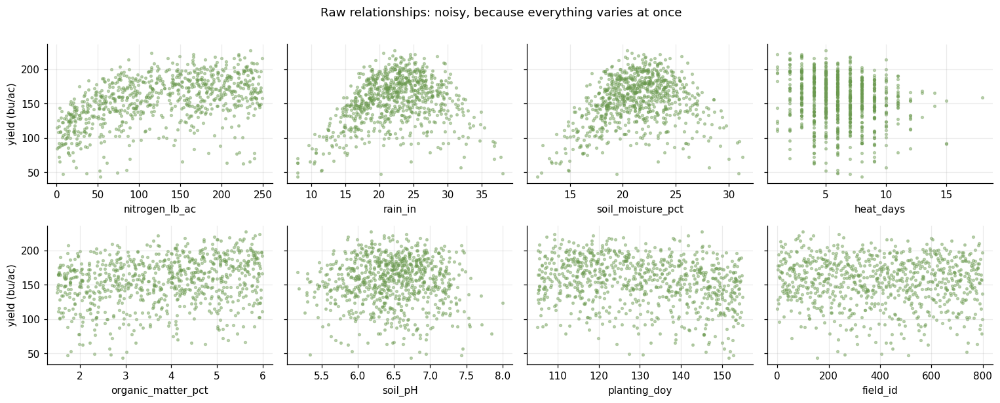

In [3]:
# 👀 First look: yield vs. each input
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharey=True)
for ax, f in zip(axes.ravel(), FEATURES):
    ax.scatter(df[f], df["yield_bu_ac"], s=6, alpha=0.4, color="#6a994e")
    ax.set_xlabel(f)
axes[0, 0].set_ylabel("yield (bu/ac)"); axes[1, 0].set_ylabel("yield (bu/ac)")
plt.suptitle("Raw relationships: noisy, because everything varies at once", y=1.01); plt.tight_layout(); plt.show()

### 1.1 Fit a linear model
$$\widehat{\text{yield}} = \beta_0 + \beta_1\,\text{N} + \beta_2\,\text{rain} + \dots$$
Each $\beta_j$ reads as: *"holding everything else constant, one more unit of $x_j$ changes predicted yield by $\beta_j$."*

In [4]:
ols = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()
lin = LinearRegression().fit(X_tr, y_tr)                 # same model, sklearn API (used later)
print(f"Linear regression  R² on held-out fields: {r2_score(y_te, lin.predict(X_te)):.3f}\n")
tbl = pd.DataFrame({"coef": ols.params, "std err": ols.bse,
                    "95% CI low": ols.conf_int()[0], "95% CI high": ols.conf_int()[1],
                    "p-value": ols.pvalues}).drop("const")
tbl.round(3)

Linear regression  R² on held-out fields: 0.460



,coef,std err,95% CI low,95% CI high,p-value
nitrogen_lb_ac,0.233,0.015,0.203,0.262,0.000
rain_in,2.428,0.884,0.691,4.164,0.006
soil_moisture_pct,-0.946,1.400,-3.695,1.804,0.500
heat_days,-2.980,0.427,-3.818,-2.141,0.000
organic_matter_pct,6.529,0.810,4.938,8.120,0.000
soil_pH,2.216,2.174,-2.054,6.487,0.308
planting_doy,-0.468,0.075,-0.616,-0.321,0.000
field_id,-0.008,0.005,-0.017,0.002,0.107


💬 *"Each extra lb of N adds about **β** bu/acre."* Sounds clear! But three traps are waiting.

### 1.2 Trap #1: units. Raw coefficients cannot be compared
A coefficient per **lb** of N and one per **pH unit** are on different scales. Standardize the inputs (z-scores) to compare them:

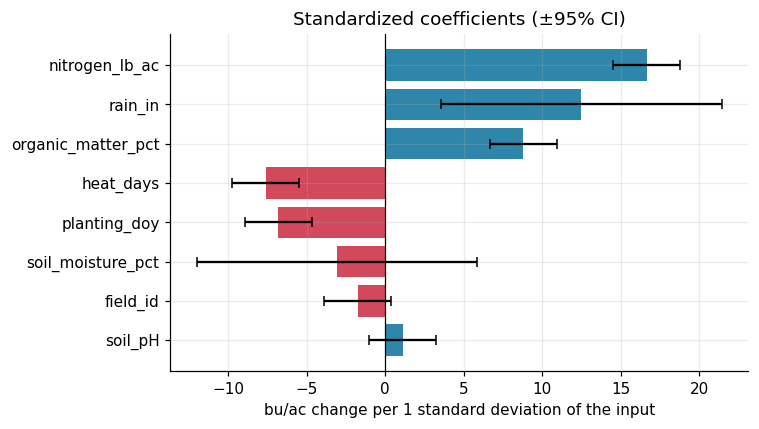

In [5]:
Z_tr = (X_tr - X_tr.mean()) / X_tr.std()
ols_z = sm.OLS(y_tr, sm.add_constant(Z_tr)).fit()
s = ols_z.params.drop("const"); ci = ols_z.conf_int().drop("const")
order = s.abs().sort_values().index
plt.figure(figsize=(7, 4))
plt.barh(order, s[order], xerr=[s[order] - ci.loc[order, 0], ci.loc[order, 1] - s[order]],
         color=[C_LIN if v < 0 else C_RF for v in s[order]], capsize=3)
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("bu/ac change per 1 standard deviation of the input"); plt.title("Standardized coefficients (±95% CI)")
plt.tight_layout(); plt.show()

🤔 **Question for the room:** the `soil_pH` coefficient is close to zero. *Does pH not matter for corn?*
(Hold that thought.) And why do `rain_in` and `soil_moisture_pct` have such wide error bars?

### 1.3 Trap #2: correlated inputs (collinearity)
Rainfall and the soil-moisture sensor carry nearly the same information. The model knows their **combined** effect,
but cannot tell how to **split** the credit between them.

Correlation(rain, soil moisture) = 0.968


,VIF (>10 = trouble)
nitrogen_lb_ac,1.0
rain_in,17.5
soil_moisture_pct,17.5
heat_days,1.0
organic_matter_pct,1.0
soil_pH,1.0
planting_doy,1.0
field_id,1.0


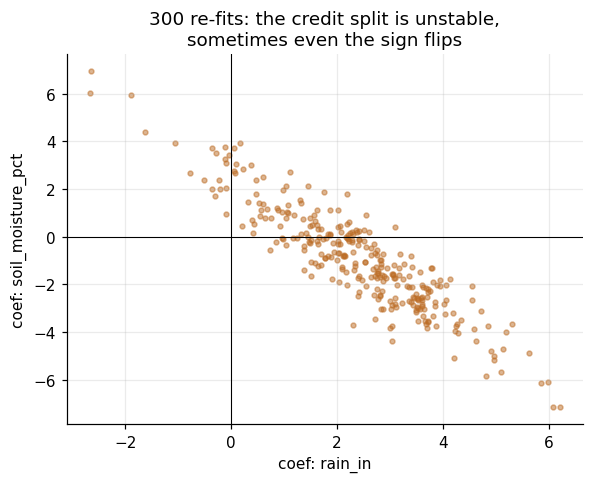

In [6]:
print("Correlation(rain, soil moisture) =", round(df["rain_in"].corr(df["soil_moisture_pct"]), 3))
vif = pd.Series([variance_inflation_factor(sm.add_constant(X_tr).values, i + 1) for i in range(len(FEATURES))],
                index=FEATURES, name="VIF (>10 = trouble)")
display(vif.round(1).to_frame())

# Re-fit on 300 bootstrap samples of 200 fields: how stable are the two coefficients?
boot = []
for b in range(300):
    idx = rng.choice(len(X_tr), 200, replace=True)
    m = LinearRegression().fit(X_tr.iloc[idx], y_tr.iloc[idx])
    boot.append(m.coef_[[FEATURES.index("rain_in"), FEATURES.index("soil_moisture_pct")]])
boot = np.array(boot)
plt.figure(figsize=(5.5, 4.5))
plt.scatter(boot[:, 0], boot[:, 1], s=10, alpha=0.5, color="#bc6c25")
plt.axhline(0, c="k", lw=.7); plt.axvline(0, c="k", lw=.7)
plt.xlabel("coef: rain_in"); plt.ylabel("coef: soil_moisture_pct")
plt.title("300 re-fits: the credit split is unstable,\nsometimes even the sign flips")
plt.tight_layout(); plt.show()

### 1.4 Trap #3: the world isn't linear
A **partial residual plot** shows what the model "thinks" one input does after removing the other inputs' effects.
The black curve is the **truth** from our answer key.

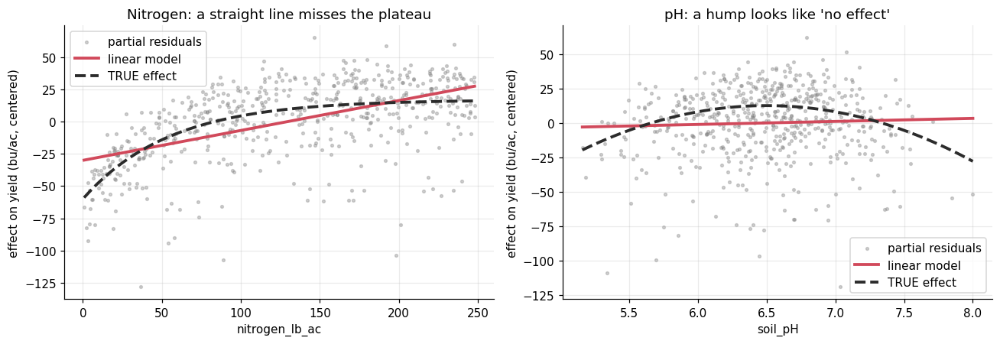

In [7]:
def true_partial(feature, grid, data):
    # True partial dependence: average true yield when everyone gets this value of the feature
    out = []
    for g in grid:
        d = data.copy(); d[feature] = g
        out.append(true_yield(d).mean())
    return np.array(out)

def model_pd(model, feature, grid, data, individual=False):
    # Partial dependence by hand (works with any scikit-learn version)
    out = []
    for g in grid:
        d = data.copy(); d[feature] = g
        out.append(model.predict(d))
    out = np.array(out).T                                   # (rows, grid)
    return out if individual else out.mean(0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, f in zip(axes, ["nitrogen_lb_ac", "soil_pH"]):
    j = FEATURES.index(f)
    pres = y_tr - lin.predict(X_tr) + lin.coef_[j] * X_tr[f]          # partial residuals
    grid = np.linspace(X_tr[f].min(), X_tr[f].max(), 60)
    truth = true_partial(f, grid, X_tr)
    ax.scatter(X_tr[f], pres - pres.mean(), s=6, alpha=.35, color="grey", label="partial residuals")
    ax.plot(grid, lin.coef_[j] * (grid - X_tr[f].mean()), color=C_LIN, lw=2.5, label="linear model")
    ax.plot(grid, truth - truth.mean(), color=C_TRUE, lw=2.5, ls="--", label="TRUE effect")
    ax.set_xlabel(f); ax.set_ylabel("effect on yield (bu/ac, centered)"); ax.legend()
axes[0].set_title("Nitrogen: a straight line misses the plateau"); axes[1].set_title("pH: a hump looks like 'no effect'")
plt.tight_layout(); plt.show()

### ✅ Part 1 takeaways
1. Coefficients are only comparable after **standardizing**.
2. With **correlated inputs**, individual coefficients are unstable. Interpret the *group*.
3. A **near-zero coefficient ≠ unimportant**. The effect may be non-linear (pH has an optimum).
4. A linear model's N story ("more is always better") is an **agronomic and economic error**. Keep it in mind for Part 2.

> A model is only as interpretable as it is *correct*. An easy-to-read but misspecified model gives you a clear, confident, **wrong** story.

---
# Part 2: Random forest: more accurate, but how do we read it?
A random forest averages hundreds of decision trees. It captures non-linearities and interactions automatically,
but no single coefficient summarizes it. We need **model-agnostic** tools.

In [8]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=0).fit(X_tr, y_tr)
print(f"Held-out R²  linear: {r2_score(y_te, lin.predict(X_te)):.3f}   random forest: {r2_score(y_te, rf.predict(X_te)):.3f}")

Held-out R²  linear: 0.460   random forest: 0.825


### 2.1 Feature importance: two popular methods, two different answers
* **Impurity importance (MDI):** sklearn's built-in `feature_importances_`, i.e. how much each feature's splits reduce error *during training*.
* **Permutation importance:** shuffle one column of the **test** data and measure how much accuracy drops. A model that relied on that column gets hurt.

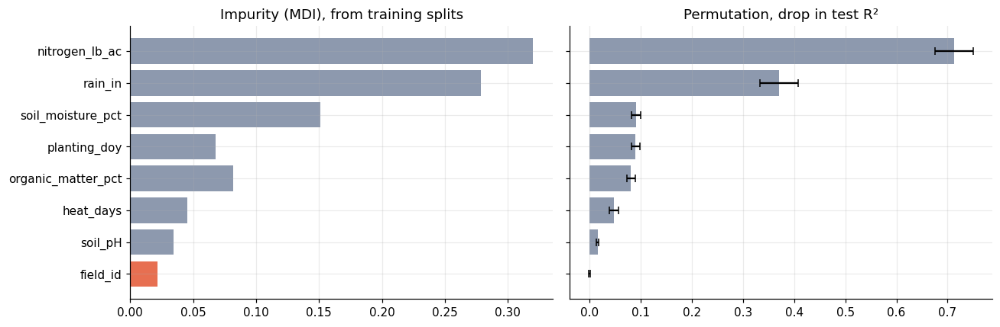

                   MDI share  permutation (ΔR²)
soil_moisture_pct      0.151              0.091
field_id               0.021              0.000
heat_days              0.045              0.048
soil_pH                0.034              0.016


In [9]:
mdi = pd.Series(rf.feature_importances_, index=FEATURES)
perm = permutation_importance(rf, X_te, y_te, n_repeats=15, random_state=0, scoring="r2")
pim = pd.Series(perm.importances_mean, index=FEATURES); pis = pd.Series(perm.importances_std, index=FEATURES)
order = pim.sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cols = ["#e76f51" if f == "field_id" else "#8d99ae" for f in order]
axes[0].barh(order, mdi[order], color=cols); axes[0].set_title("Impurity (MDI), from training splits")
axes[1].barh(order, pim[order], xerr=pis[order], color=cols, capsize=3); axes[1].set_title("Permutation, drop in test R²")
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()
print(pd.DataFrame({"MDI share": mdi, "permutation (ΔR²)": pim}).loc[["soil_moisture_pct", "field_id", "heat_days", "soil_pH"]].round(3))

🔎 **What happened?**
* `soil_moisture_pct` has **no causal effect** on yield, yet both methods give it credit: it stands in for its twin, `rain_in`.
  Importance describes what the **model** uses, not what drives the **crop**.
* `field_id` is pure noise, yet **MDI gives it credit** comparable to real drivers like heat stress and pH. Impurity importance favors
  features with many unique values, because trees can always find *some* split on them that fits training noise.
  Permutation on **held-out** data correctly says ≈ 0.
* `soil_pH` now shows up as **important**: the forest captured the hump the linear model missed.
* ⚠️ Because `rain_in` and `soil_moisture_pct` **share** the credit, shuffling one hurts less than it should: the other covers for it.
  Fix: permute **correlated features as a group**. The group's importance is larger than the two individual numbers added together.

In [10]:
def grouped_perm(model, X, y, cols, reps=15, seed=0):
    r = np.random.default_rng(seed); base = r2_score(y, model.predict(X)); drops = []
    for _ in range(reps):
        Xp = X.copy(); idx = r.permutation(len(X))
        Xp[cols] = X[cols].values[idx]                 # shuffle the columns *together*
        drops.append(base - r2_score(y, model.predict(Xp)))
    return np.mean(drops)

print(f"rain alone:           {pim['rain_in']:.3f}")
print(f"soil moisture alone:  {pim['soil_moisture_pct']:.3f}")
print(f"rain + soil moisture: {grouped_perm(rf, X_te, y_te, ['rain_in', 'soil_moisture_pct']):.3f}  ← the 'water' signal")

rain alone:           0.371
soil moisture alone:  0.091
rain + soil moisture: 0.713  ← the 'water' signal


### 2.2 Partial dependence: *how* does each input act?
**Partial dependence (PD):** set every field to the same value of one input (e.g. N = 100) and average the predictions,
then repeat across a grid of values. The result is the model's *average* response curve.
Let's compare **random forest vs. linear vs. the TRUTH**.

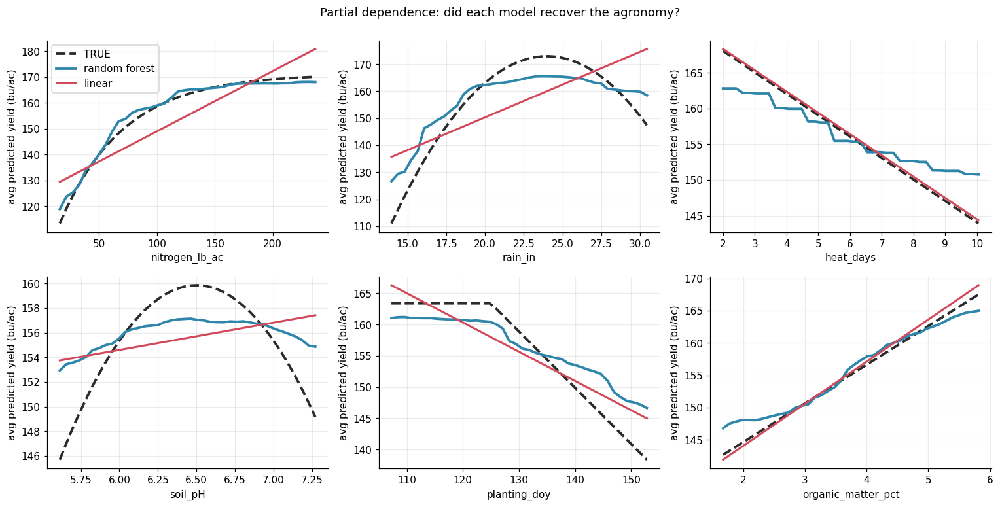

In [11]:
show = ["nitrogen_lb_ac", "rain_in", "heat_days", "soil_pH", "planting_doy", "organic_matter_pct"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), show):
    grid = np.linspace(*np.percentile(X_tr[f], [5, 95]), 40)
    rf_curve = model_pd(rf, f, grid, X_tr); lin_curve = model_pd(lin, f, grid, X_tr)
    truth = true_partial(f, grid, X_tr)
    ax.plot(grid, truth, color=C_TRUE, ls="--", lw=2.5, label="TRUE")
    ax.plot(grid, rf_curve, color=C_RF, lw=2.5, label="random forest")
    ax.plot(grid, lin_curve, color=C_LIN, lw=2, label="linear")
    ax.set_xlabel(f); ax.set_ylabel("avg predicted yield (bu/ac)")
axes[0, 0].legend(); plt.suptitle("Partial dependence: did each model recover the agronomy?", y=1.0)
plt.tight_layout(); plt.show()

### 2.3 ICE curves: one curve *per field*, revealing interactions
Partial dependence is an **average**, and averages can hide things. **ICE (Individual Conditional Expectation)** draws one curve
per field. Below, each field's N-response curve is colored by **that field's rainfall**.

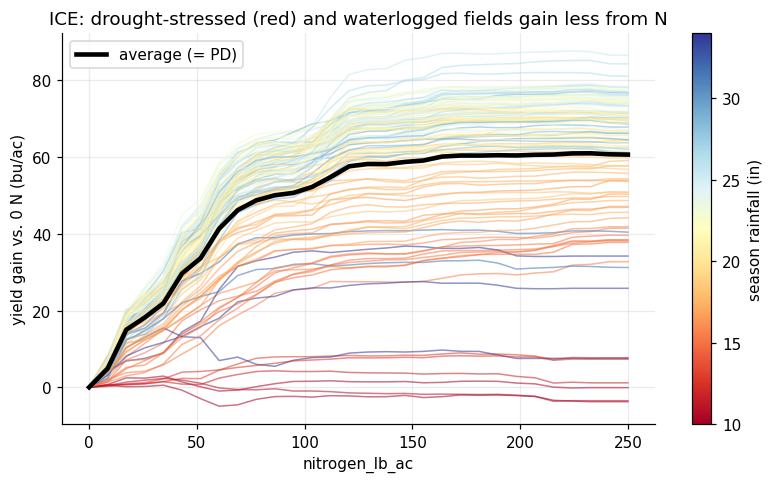

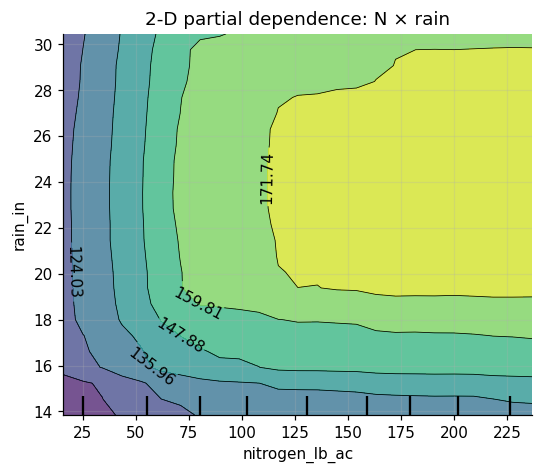

In [12]:
sub = X_te.sample(120, random_state=1)
grid = np.linspace(0, 250, 30)
curves = model_pd(rf, "nitrogen_lb_ac", grid, sub, individual=True)
curves = curves - curves[:, [0]]                          # center at N = 0: "gain from N"
fig, ax = plt.subplots(figsize=(7.5, 4.5))
norm = plt.Normalize(10, 34); cmap = plt.cm.RdYlBu
for c, r in zip(curves, sub["rain_in"]):
    ax.plot(grid, c, color=cmap(norm(r)), alpha=.55, lw=1)
ax.plot(grid, curves.mean(0), color="k", lw=3, label="average (= PD)")
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="season rainfall (in)")
ax.set_xlabel("nitrogen_lb_ac"); ax.set_ylabel("yield gain vs. 0 N (bu/ac)"); ax.legend()
ax.set_title("ICE: drought-stressed (red) and waterlogged fields gain less from N")
plt.tight_layout(); plt.show()

PartialDependenceDisplay.from_estimator(rf, X_tr, [("nitrogen_lb_ac", "rain_in")], grid_resolution=25)
plt.gcf().set_size_inches(5.5, 4.5); plt.title("2-D partial dependence: N × rain"); plt.show()

### 2.4 🎛️ Live "what-if" for one field (local explanation)
Move the sliders. Try pushing **N beyond 250 lb/ac** (outside the training data) and watch how each model *extrapolates*.

In [13]:
import ipywidgets as w
base = X_te.iloc[0].copy()
def what_if(nitrogen=150, rain=22.0, heat_days=6, pH=6.4, planting_doy=125):
    f = base.copy(); f[["rain_in", "heat_days", "soil_pH", "planting_doy"]] = [rain, heat_days, pH, planting_doy]
    f["soil_moisture_pct"] = 8 + 0.6 * rain
    Ns = np.linspace(0, 400, 81)
    G = pd.DataFrame([f] * len(Ns)); G["nitrogen_lb_ac"] = Ns
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.axvspan(250, 400, color="grey", alpha=.12, label="no training data here")
    ax.plot(Ns, true_yield(G), "--", color=C_TRUE, lw=2.5, label="TRUE")
    ax.plot(Ns, rf.predict(G), color=C_RF, lw=2.5, label="random forest")
    ax.plot(Ns, lin.predict(G), color=C_LIN, lw=2, label="linear")
    ax.axvline(nitrogen, color="k", lw=.8)
    G1 = G.iloc[[0]].copy(); G1["nitrogen_lb_ac"] = nitrogen
    ax.set_title(f"This field @ N={nitrogen}: truth {true_yield(G1).iloc[0]:.0f} | RF {rf.predict(G1)[0]:.0f} | "
                 f"linear {lin.predict(G1)[0]:.0f} bu/ac")
    ax.set_xlabel("nitrogen_lb_ac"); ax.set_ylabel("yield (bu/ac)"); ax.set_ylim(60, 260); ax.legend(loc="lower right")
    plt.show()
w.interact(what_if,
           nitrogen=w.IntSlider(value=150, min=0, max=400, step=10, continuous_update=False),
           rain=w.FloatSlider(value=22, min=8, max=38, step=1, continuous_update=False),
           heat_days=w.IntSlider(value=6, min=0, max=25, step=1, continuous_update=False),
           pH=w.FloatSlider(value=6.4, min=5.0, max=8.0, step=0.1, continuous_update=False),
           planting_doy=w.IntSlider(value=125, min=105, max=155, step=1, continuous_update=False));

interactive(children=(IntSlider(value=150, continuous_update=False, description='nitrogen', max=400, step=10),…

### 2.5 💵 From interpretation to a decision: the economic N rate
This is the same idea as ISU's *Corn Nitrogen Rate Calculator*: apply N until the last pound no longer pays for itself.

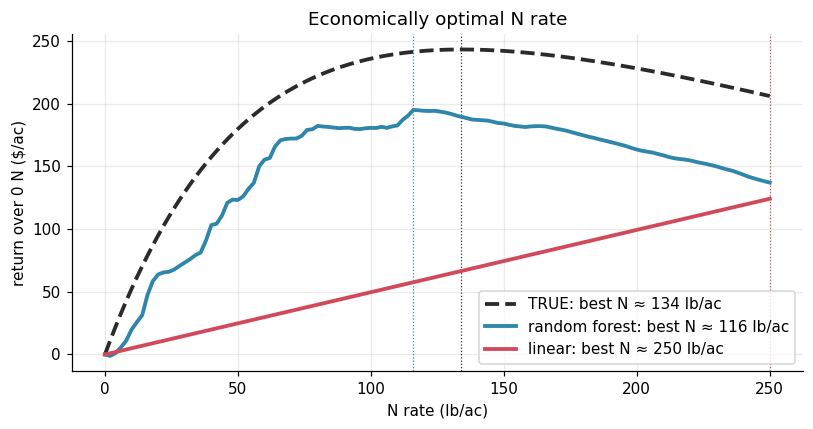

In [14]:
corn_price, n_price = 4.50, 0.55          # $/bu, $/lb N: change these!
Ns = np.linspace(0, 250, 126)
curves = {"TRUE": true_partial("nitrogen_lb_ac", Ns, X_tr),
          "random forest": model_pd(rf, "nitrogen_lb_ac", Ns, X_tr),
          "linear": model_pd(lin, "nitrogen_lb_ac", Ns, X_tr)}
plt.figure(figsize=(7.5, 4))
for (name, yv), c in zip(curves.items(), [C_TRUE, C_RF, C_LIN]):
    profit = corn_price * yv - n_price * Ns
    best = Ns[np.argmax(profit)]
    plt.plot(Ns, profit - profit[0], color=c, lw=2.5, ls="--" if name == "TRUE" else "-", label=f"{name}: best N ≈ {best:.0f} lb/ac")
    plt.axvline(best, color=c, lw=.8, ls=":")
plt.xlabel("N rate (lb/ac)"); plt.ylabel("return over 0 N ($/ac)"); plt.legend(); plt.title("Economically optimal N rate")
plt.tight_layout(); plt.show()

### ✅ Part 2 takeaways
1. Prefer **permutation importance on held-out data** over impurity importance. Watch for ID-like columns.
2. For correlated features, use **grouped** importance.
3. **PD** shows the average response (note: the forest *under*-estimates heat stress above ~10 days, because few fields are there and trees average them away. Here the simple linear model is right!); **ICE** reveals heterogeneity and interactions (N × rain).
4. Tree models **flat-line** outside the training range; linear models extrapolate forever. Neither is "right", so know your data's support.
5. Interpretation drives **decisions**: the linear model would tell every grower to apply the maximum N.

> ⚠️ These tools explain the **model**, not causality in the field. Our N data came from a *randomized* "trial", which is why the PD curve has a causal reading here. With observational farm data, be careful.

---
# Part 3: Deep learning: what does a neural network *see*?
We'll use **GoogLeNet (Inception v1)**, a convolutional neural net trained on 1.2 M ImageNet photos (1,000 classes, including
`corn`, `ear`, `rapeseed`, `tractor`, `harvester`, `hay`). It is the classic model from the *Feature Visualization* work of Olah et al. (Distill, 2017).

Two complementary questions:
1. **Attribution:** *where* in this photo did the network look? → **Grad-CAM**
2. **Feature visualization:** *what* is a given neuron looking for? → **activation maximization**: start from noise and change the
   **image** (not the weights!) by gradient ascent until the neuron fires as strongly as possible.

In [15]:
#@title ⚙️ Load the pretrained network + helper functions
import torch, torch.nn.functional as F, requests, io, urllib.parse, random
from PIL import Image
from torchvision.models import googlenet, GoogLeNet_Weights
import torchvision.transforms as T

device = "cuda" if torch.cuda.is_available() else "cpu"
weights = GoogLeNet_Weights.IMAGENET1K_V1
model = googlenet(weights=weights).eval().to(device)
for p in model.parameters(): p.requires_grad_(False)
CATS = weights.meta["categories"]
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
to_224 = T.Compose([T.Resize(224), T.CenterCrop(224)])
print("Device:", device, "| ag-related ImageNet classes:",
      [c for c in ["corn", "ear", "rapeseed", "tractor", "harvester", "thresher", "plow", "hay", "strawberry"] if c in CATS])

def load_commons(fnames):
    # Download a freely licensed photo from Wikimedia Commons, trying backup files and thumbnail sizes
    fnames = [fnames] if isinstance(fnames, str) else fnames
    for fname in fnames:
        for suffix in ["?width=960", "?width=500", ""]:
            url = "https://commons.wikimedia.org/wiki/Special:FilePath/" + urllib.parse.quote(fname) + suffix
            try:
                r = requests.get(url, headers={"User-Agent": "ISU-TrAC-interpretability-course/1.0 (educational use)"}, timeout=30)
                r.raise_for_status()
                return Image.open(io.BytesIO(r.content)).convert("RGB")
            except Exception as e:
                last = e
    raise RuntimeError(f"all downloads failed: {last}")

def to_tensor(img):          # PIL -> normalized 1x3x224x224 tensor
    return ((T.ToTensor()(to_224(img)).unsqueeze(0).to(device)) - MEAN) / STD

@torch.no_grad()
def top5(img):
    p = model(to_tensor(img)).softmax(-1)[0]; v, i = p.topk(5)
    return [(CATS[k], float(s)) for s, k in zip(v, i)]

def grad_cam(img, cls, layer):
    # Grad-CAM: weight each feature map by how much the class score depends on it
    store = {}
    def hook(m, i, o): o.retain_grad(); store["a"] = o
    h = layer.register_forward_hook(hook)
    x = to_tensor(img).requires_grad_(True)
    score = model(x)[0, CATS.index(cls)]; score.backward(); h.remove()
    a, g = store["a"], store["a"].grad
    cam = F.relu((g.mean(dim=(2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()

# ---------- feature visualization (Fourier-parameterized image + transformation robustness, a la Lucid/Lucent)
COLOR = torch.tensor([[0.26, 0.09, 0.02], [0.27, 0.00, -0.05], [0.27, -0.09, 0.03]])
COLOR = (COLOR / COLOR.norm(dim=0).max()).to(device)

def fourier_image(n, size, sd=0.01):
    fy = np.fft.fftfreq(size)[:, None]; fx = np.fft.fftfreq(size)[: size // 2 + 1]
    scale = 1.0 / np.maximum(np.sqrt(fx ** 2 + fy ** 2), 1.0 / size)          # favor low frequencies
    scale = torch.tensor(scale, dtype=torch.float32, device=device)[None, None, :, :, None]
    spec = (torch.randn(n, 3, size, size // 2 + 1, 2, device=device) * sd).requires_grad_(True)
    def render():
        img = torch.fft.irfftn(torch.view_as_complex(scale * spec), s=(size, size), dim=(-2, -1), norm="ortho") / 4
        img = torch.einsum("nchw,dc->ndhw", img, COLOR)                          # decorrelated colors
        return torch.sigmoid(img)
    return spec, render

def random_transform(img):
    def jitter(x, d):
        dx, dy = np.random.randint(0, d + 1, 2); return x[..., dy:x.shape[-2] - d + dy, dx:x.shape[-1] - d + dx]
    img = F.pad(img, (12, 12, 12, 12), mode="constant", value=0.5)
    img = jitter(img, 8)
    img = F.interpolate(img, scale_factor=random.choice([0.95, 0.975, 1.0, 1.025, 1.05]), mode="bilinear", align_corners=False)
    a = np.deg2rad(random.uniform(-5, 5))
    theta = torch.tensor([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0]], dtype=torch.float32, device=device)
    grid = F.affine_grid(theta.expand(img.shape[0], 2, 3), img.shape, align_corners=False)
    img = F.grid_sample(img, grid, padding_mode="border", align_corners=False)
    return jitter(img, 4)

STEPS = 256 if device == "cuda" else 96
SIZE = 224 if device == "cuda" else 160

def visualize(objective_fn, n, steps=STEPS, size=SIZE, lr=0.05):
    spec, render = fourier_image(n, size)
    opt = torch.optim.Adam([spec], lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        x = (random_transform(render()) - MEAN) / STD
        loss = -objective_fn(x); loss.backward(); opt.step()
    return render().detach().permute(0, 2, 3, 1).cpu().numpy()

def channel_objective(layer, channels):
    # maximize mean activation of channel channels[i] for image i in the batch
    def obj(x):
        store = {}
        h = layer.register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
        model(x); h.remove()
        a = store["a"]
        return torch.stack([a[i, c].mean() for i, c in enumerate(channels)]).sum()
    return obj

def class_objective(classes):
    idx = [CATS.index(c) for c in classes]
    return lambda x: model(x)[torch.arange(len(idx)), idx].sum()

def show_grid(imgs, titles, cols=None, size=2.6):
    cols = cols or len(imgs); rows = int(np.ceil(len(imgs) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows + .3), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, im, t in zip(axes.ravel(), imgs, titles): ax.imshow(im); ax.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()
print("Helpers ready ✔")

Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 121MB/s]


Device: cuda | ag-related ImageNet classes: ['corn', 'ear', 'rapeseed', 'tractor', 'harvester', 'thresher', 'plow', 'hay', 'strawberry']
Helpers ready ✔


### 3.1 What does the network predict?
Photos from Wikimedia Commons (freely licensed): USDA-ARS maize ears and a John Deere tractor pulling a chisel plow.
*Have your own field photo? See the bonus cell at the end.*

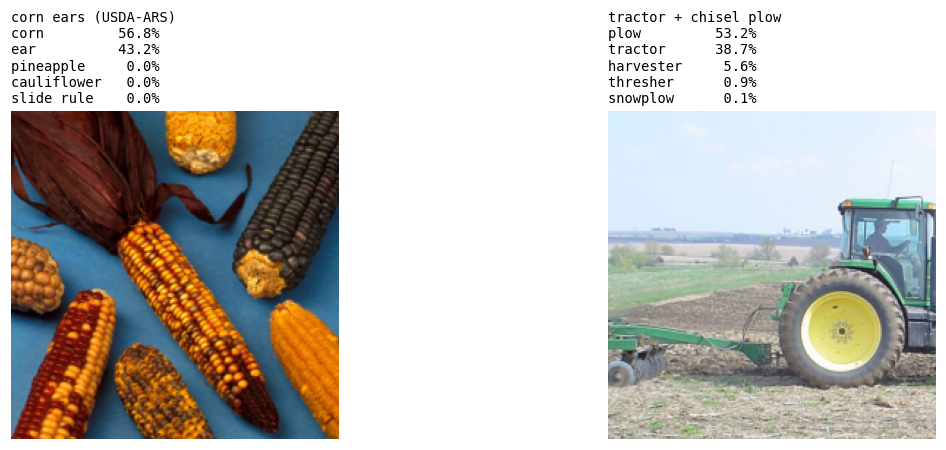

In [16]:
PHOTOS = {"corn ears (USDA-ARS)": ["Zea_mays.jpg", "YellowCorn.jpg"],                       # first choice, backup
          "tractor + chisel plow": ["JDTractor_chisel-plough.jpg", "John_Deere_8320.jpg"]}
imgs = {}
for name, f in PHOTOS.items():
    try: imgs[name] = load_commons(f)
    except Exception as e: print(f"⚠️ could not download {f[0]} ({e}). Use the upload cell at the bottom instead.")

fig, axes = plt.subplots(1, len(imgs), figsize=(6 * len(imgs), 4.2), squeeze=False)
for ax, (name, im) in zip(axes[0], imgs.items()):
    ax.imshow(to_224(im)); ax.axis("off")
    ax.set_title(name + "\n" + "\n".join(f"{c:<12s} {p:5.1%}" for c, p in top5(im)), fontsize=9, family="monospace", loc="left")
plt.tight_layout(); plt.show()

### 3.2 Attribution with Grad-CAM: *where* is the evidence?
Grad-CAM takes the last convolutional layer (7×7 feature maps), weights each map by how much the **chosen class score** depends on it,
and overlays the result. The same photo, asked two different questions:

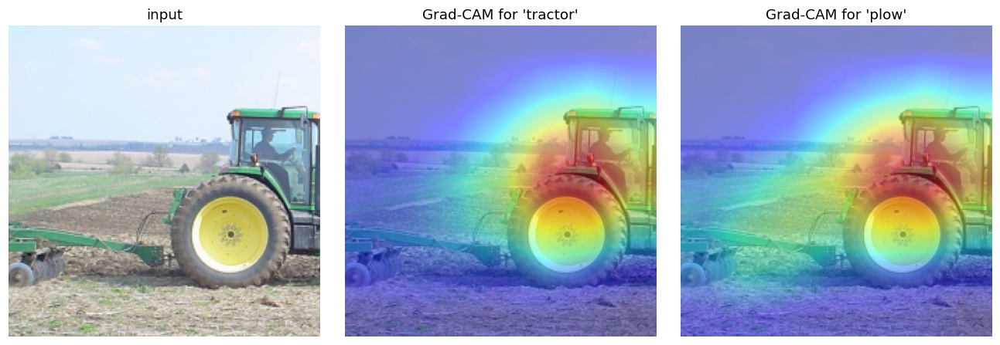

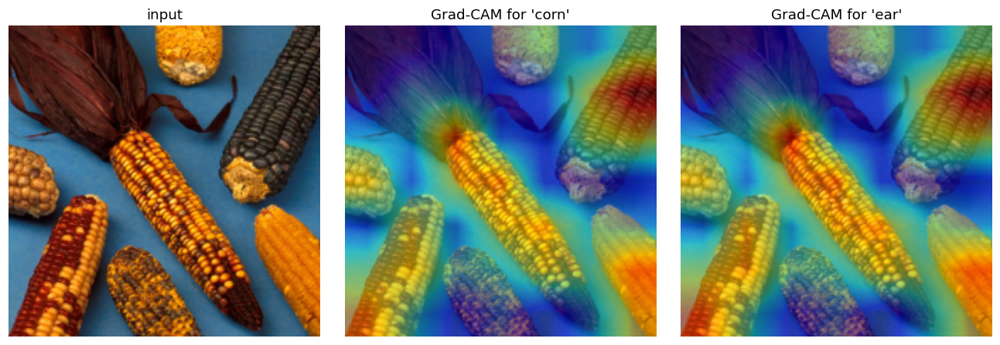

In [17]:
def cam_panel(img, classes, layer=model.inception5b):
    base = np.asarray(to_224(img)) / 255
    fig, axes = plt.subplots(1, len(classes) + 1, figsize=(4 * (len(classes) + 1), 4))
    axes[0].imshow(base); axes[0].set_title("input")
    for ax, c in zip(axes[1:], classes):
        ax.imshow(base); ax.imshow(grad_cam(img, c, layer), cmap="jet", alpha=.45)
        ax.set_title(f"Grad-CAM for '{c}'")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

if "tractor + chisel plow" in imgs: cam_panel(imgs["tractor + chisel plow"], ["tractor", "plow"])
if "corn ears (USDA-ARS)" in imgs:  cam_panel(imgs["corn ears (USDA-ARS)"], ["corn", "ear"])

### 3.3 Feature visualization: what does a *neuron* want to see?
We start from random noise and run gradient ascent on the **pixels** to maximize one channel's activation.
To get natural-looking images, we optimize in frequency space and require the image to keep working under small jitters, scales and rotations
(the "transformation robustness" trick from the Distill article).

Watch the features grow more complex with depth: **edges/colors → textures → patterns → object parts**.

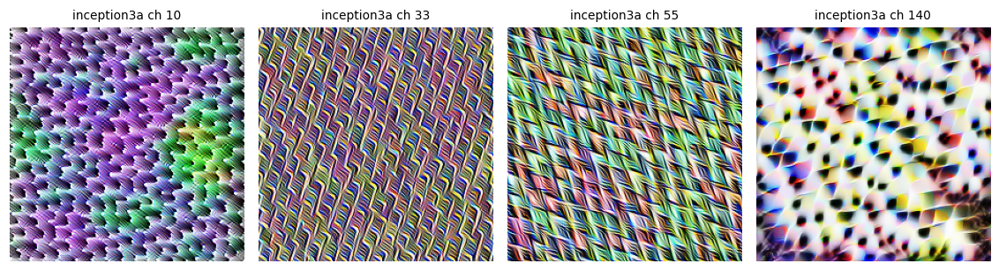

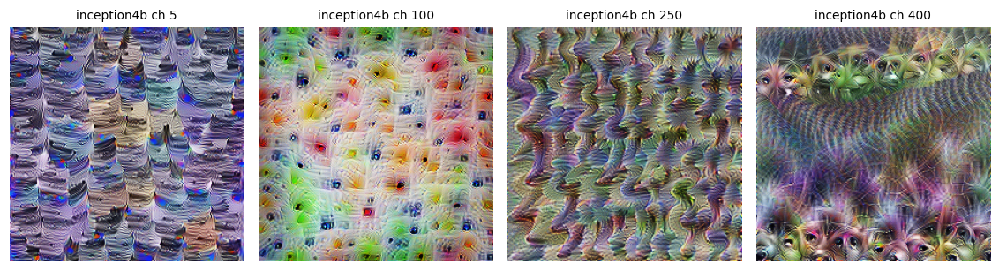

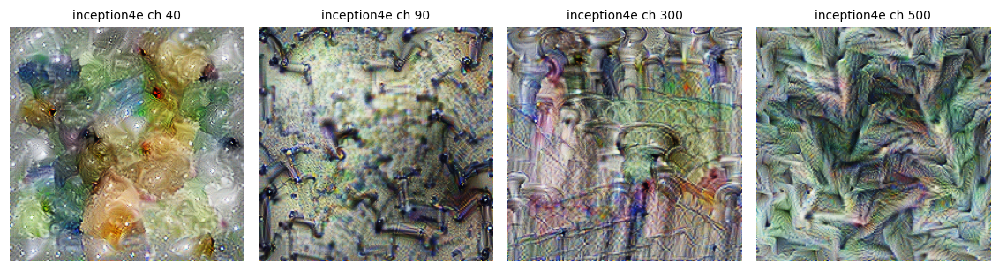

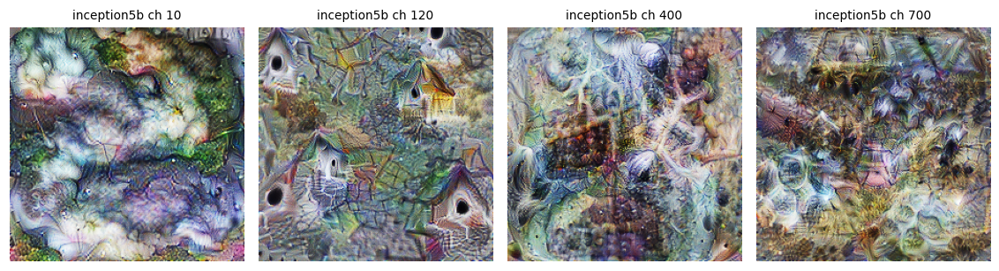

In [18]:
LAYERS = {"inception3a (early)": (model.inception3a, [10, 33, 55, 140]),
          "inception4b (middle)": (model.inception4b, [5, 100, 250, 400]),
          "inception4e (deep)":   (model.inception4e, [40, 90, 300, 500]),
          "inception5b (deepest)": (model.inception5b, [10, 120, 400, 700])}
for name, (layer, chans) in LAYERS.items():
    ims = visualize(channel_objective(layer, chans), n=len(chans))
    show_grid(ims, [f"{name.split()[0]} ch {c}" for c in chans])
# 👉 Try it: change the channel numbers and re-run (3a: 0-255, 4b: 0-511, 4e: 0-831, 5b: 0-1023)

### 3.4 🌽 Putting the two together: which neurons fire on our corn photo, and what do they look for?
We find the channels in a middle layer that respond **most strongly** to the corn photo, then show (a) **where** in the photo they fire
and (b) **what** they want to see. This is how researchers build up a "vocabulary" of a network's concepts.

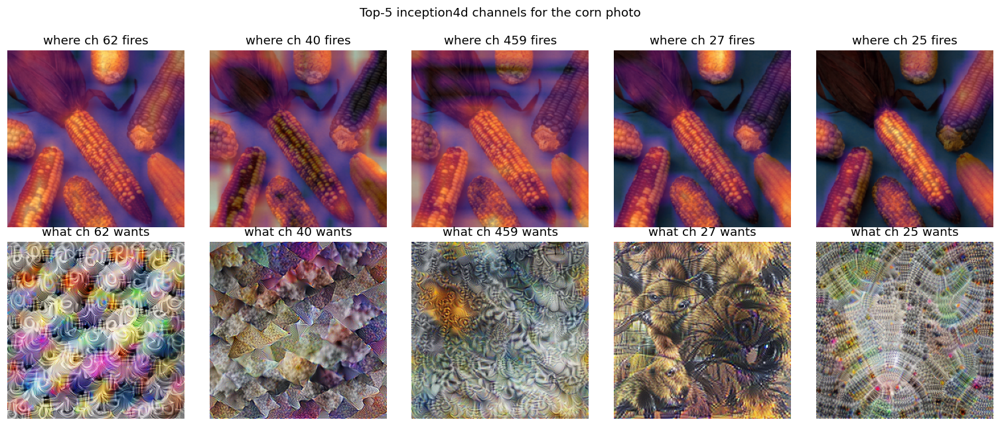

In [19]:
if "corn ears (USDA-ARS)" in imgs:
    img = imgs["corn ears (USDA-ARS)"]; layer = model.inception4d; store = {}
    h = layer.register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
    with torch.no_grad(): model(to_tensor(img))
    h.remove()
    act = store["a"][0]                                    # (channels, 14, 14)
    top = act.mean(dim=(1, 2)).topk(5).indices.tolist()
    vis = visualize(channel_objective(layer, top), n=len(top))
    base = np.asarray(to_224(img)) / 255
    fig, axes = plt.subplots(2, len(top), figsize=(2.8 * len(top), 5.8))
    for k, c in enumerate(top):
        m = F.interpolate(act[c][None, None], size=(224, 224), mode="bilinear")[0, 0].cpu().numpy()
        axes[0, k].imshow(base); axes[0, k].imshow(m / m.max(), cmap="magma", alpha=.55); axes[0, k].set_title(f"where ch {c} fires")
        axes[1, k].imshow(vis[k]); axes[1, k].set_title(f"what ch {c} wants")
    for ax in axes.ravel(): ax.axis("off")
    plt.suptitle("Top-5 inception4d channels for the corn photo", y=1.0); plt.tight_layout(); plt.show()

### 3.5 What does the network think a "corn" or a "tractor" looks like?
Now maximize the **class score** instead of a single neuron.

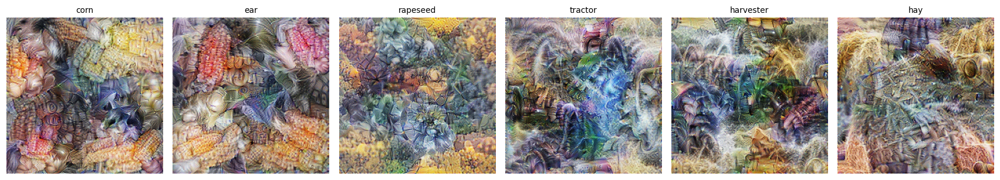

In [20]:
classes = ["corn", "ear", "rapeseed", "tractor", "harvester", "hay"]
show_grid(visualize(class_objective(classes), n=len(classes)), classes, cols=6)

💬 **Discussion**
* ImageNet's `corn` is mostly **ears on a plate or at a market**, not a V6 canopy or a field from a drone. An off-the-shelf model's
  concepts reflect its **training data**, not agronomy. That is why ag models need domain data and fine-tuning.
* Feature visualizations are **hypotheses, not proofs**: many neurons are *polysemantic* (respond to several unrelated things).
  Check them against real images that activate the neuron, as we did in 3.4.
* For a disease classifier, the same tools can expose a **shortcut**: Grad-CAM on the background instead of the lesion is a red flag.

In [21]:
#@title 📷 Bonus: try your own field photo (upload a .jpg/.png)
try:
    from google.colab import files
    up = files.upload()
    for fname, data in up.items():
        my = Image.open(io.BytesIO(data)).convert("RGB")
        print(fname, "→", ", ".join(f"{c} ({p:.0%})" for c, p in top5(my)))
        cam_panel(my, [top5(my)[0][0]])
except ImportError:
    print("Upload works in Google Colab. Elsewhere: my = Image.open('photo.jpg'); cam_panel(my, ['corn'])")

KeyboardInterrupt: 

---
# Wrap-up 🎯

### Reveal the answer key

In [ ]:
print('''TRUE yield model used to simulate the fields:
  yield = 110
        + 90·(1 − e^(−N/55)) · rain_ok          ← N plateau, weaker in drought/flood (interaction)
        − 0.25·(rain − 24)²                      ← optimum rain ≈ 24 in
        − 3.0·heat_days                          ← heat stress
        + 6.0·organic_matter                     ← soil OM
        − 18·(pH − 6.5)²                         ← optimum pH ≈ 6.5
        − 0.9·max(planting_doy − 125, 0)         ← late-planting penalty after ~May 5
        + noise(sd = 10)
  soil_moisture_pct: NO direct effect (it just tracks rain)
  field_id:          NO effect at all''')

| Method | Answers | Watch out for |
|---|---|---|
| Linear coefficients | direction & size of a (linear) effect | units, collinearity, non-linearity |
| Impurity importance (MDI) | what the trees split on | inflated for ID-like / high-cardinality features |
| Permutation importance | what the model *needs* on new data | correlated features share credit → group them |
| Partial dependence / ICE | *how* an input moves predictions | averages hide interactions; extrapolation |
| Grad-CAM | *where* the evidence is in an image | coarse (7×7) resolution; shows correlation, not cause |
| Feature visualization | *what* a neuron or class detects | polysemantic neurons; treat as hypotheses |

**Three questions to take back to your team**
1. Would your agronomists agree with your model's partial dependence curves? If not, who is wrong?
2. Is there a `field_id`-type column (date, plot number, sensor serial) quietly helping your model?
3. When your image model is right, is it right **for the right reason**?

📚 *Further reading:* Molnar, **Interpretable Machine Learning** (free online book) · Olah et al., **Feature Visualization**, Distill (2017) ·
Selvaraju et al., **Grad-CAM** (ICCV 2017)